# Régression logistique : prédire l'admission d'un étudiant

Ce projet implémente une **régression logistique from scratch** avec NumPy pour prédire si un étudiant est admis dans une université à partir de ses notes à deux examens.

Au programme :
1. Exploration et visualisation des données
2. Formulation probabiliste du modèle (maximum de vraisemblance)
3. Implémentation vectorisée de la sigmoïde, de la fonction de coût et de son gradient
4. Entraînement avec un optimiseur (`scipy.optimize`) puis avec une **descente de gradient codée à la main**
5. Visualisation de la frontière de décision et évaluation du modèle
6. Comparaison avec l'implémentation de scikit-learn

In [9]:
pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 9.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 7.7 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 474.0/474.0 kB 3.6 MB/s eta 0:00:00a 0:00:01m

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as op
from sklearn.linear_model import LogisticRegression

## 1. Les données

Chaque ligne du fichier correspond à un étudiant : note à l'examen 1, note à l'examen 2, et décision d'admission (1 = admis, 0 = refusé).

In [11]:
data = np.loadtxt('data/data1.txt', delimiter=',')

X_raw = data[:, :2]   # notes aux deux examens
y = data[:, 2]        # étiquette : 1 = admis, 0 = refusé
m = y.size            # nombre d'exemples

print(f"{m} étudiants, dont {int(y.sum())} admis ({y.mean():.0%})")

100 étudiants, dont 60 admis (60%)


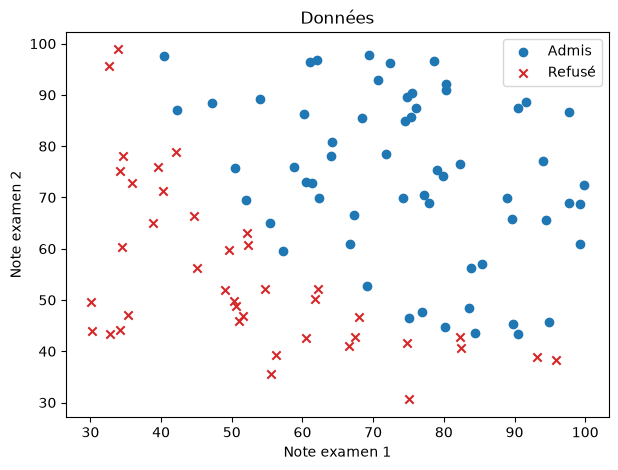

In [12]:
def plot_data(X, y, ax=None):
    """Nuage de points des deux classes."""
    ax = ax or plt.gca()
    pos, neg = (y == 1), (y == 0)
    ax.scatter(X[pos, 0], X[pos, 1], marker='o', c='tab:blue', label='Admis')
    ax.scatter(X[neg, 0], X[neg, 1], marker='x', c='tab:red', label='Refusé')
    ax.set_xlabel('Note examen 1')
    ax.set_ylabel('Note examen 2')
    ax.legend()
    return ax

plt.figure(figsize=(7, 5))
plot_data(X_raw, y)
plt.title('Données')
plt.show()

Les deux classes semblent séparables par une droite : un modèle linéaire comme la régression logistique est un bon candidat.

On ajoute une colonne de 1 à la matrice des variables pour intégrer le terme constant $\theta_0$ : chaque ligne devient $x = (1, x_1, x_2)$, et $x^\top\theta = \theta_0 + \theta_1 x_1 + \theta_2 x_2$.

In [13]:
X = np.column_stack([np.ones(m), X_raw])
X.shape

(100, 3)

## 2. Le modèle

On observe $(x_i, y_i)_{1 \le i \le m}$ i.i.d. avec $x_i \in \mathbb{R}^p$ et $y_i \in \{0, 1\}$. On suppose que

$$
Y \mid X = x \;\sim\; \mathrm{Bernoulli}\big(\sigma(x^\top\theta)\big),
\qquad \sigma(z) = \frac{1}{1 + e^{-z}}
$$

La sigmoïde $\sigma$ envoie $\mathbb{R}$ dans $]0, 1[$ : $\sigma(x^\top\theta)$ s'interprète comme la probabilité d'être admis.

### Maximum de vraisemblance

La probabilité d'observer $y_i$ sachant $x_i$ vaut $\sigma(x_i^\top\theta)^{y_i}\,\big(1-\sigma(x_i^\top\theta)\big)^{1-y_i}$. Maximiser la vraisemblance revient à minimiser la log-vraisemblance négative moyenne, appelée **entropie croisée binaire** :

$$
J(\theta) = -\frac{1}{m}\sum_{i=1}^m \Big[ y_i \log \sigma(x_i^\top\theta) + (1-y_i)\log\big(1-\sigma(x_i^\top\theta)\big) \Big]
$$

### Forme matricielle

En notant $h = \sigma(X\theta) \in \mathbb{R}^m$ (sigmoïde appliquée composante par composante) :

$$
J(\theta) = -\frac{1}{m}\Big[ y^\top \log h + (1-y)^\top \log(1-h) \Big]
$$

### Gradient

Grâce à l'identité $\sigma'(z) = \sigma(z)\,(1-\sigma(z))$, on obtient une expression très simple :

$$
\nabla_\theta J(\theta) = \frac{1}{m} X^\top\big(\sigma(X\theta) - y\big)
$$

$J$ est convexe : tout minimum local est global, ce qui garantit la convergence des méthodes de gradient.

## 3. Implémentation

In [14]:
def sigmoid(z):
    """Fonction sigmoïde, appliquée composante par composante."""
    return 1.0 / (1.0 + np.exp(-z))


def logit(p):
    """Réciproque de la sigmoïde, définie sur ]0, 1[."""
    return np.log(p / (1 - p))


def compute_cost(theta, X, y):
    """Entropie croisée binaire J(theta), forme vectorisée."""
    m = y.size
    h = sigmoid(X @ theta)
    eps = 1e-12  # évite log(0)
    return -(y @ np.log(h + eps) + (1 - y) @ np.log(1 - h + eps)) / m


def compute_grad(theta, X, y):
    """Gradient de J par rapport à theta."""
    m = y.size
    return X.T @ (sigmoid(X @ theta) - y) / m


def predict_proba(theta, X):
    """Probabilité prédite d'appartenir à la classe 1."""
    return sigmoid(X @ theta)


def predict(theta, X, threshold=0.5):
    """Classe prédite (0 ou 1) avec un seuil de décision."""
    return (predict_proba(theta, X) >= threshold).astype(int)

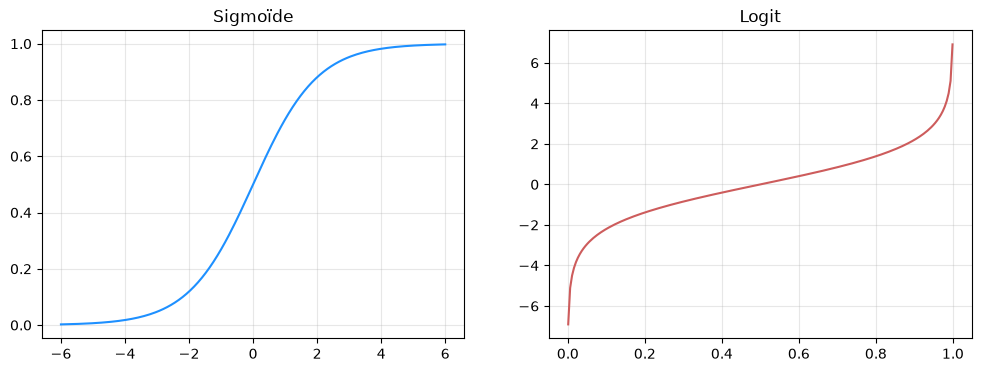

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
z = np.linspace(-6, 6, 200)
ax[0].plot(z, sigmoid(z), color='dodgerblue')
ax[0].set_title('Sigmoïde')
p = np.linspace(0.001, 0.999, 200)
ax[1].plot(p, logit(p), color='indianred')
ax[1].set_title('Logit')
for a in ax:
    a.grid(alpha=0.3)
plt.show()

### Tests unitaires

In [16]:
# Sigmoïde
assert abs(sigmoid(0.5) - 0.622459) < 1e-5
assert np.allclose(sigmoid(np.array([1, -1, 0.5])), [0.73105858, 0.26894142, 0.62245933])

# Coût : avec theta = 0, toutes les probabilités valent 0.5, donc J = log(2)
assert abs(compute_cost(np.zeros(3), X, y) - np.log(2)) < 1e-6

# Gradient : comparaison avec une approximation par différences finies
theta_test = np.array([-0.01, 0.05, 0.0])
num_grad = op.approx_fprime(theta_test, compute_cost, 1e-6, X, y)
assert np.allclose(num_grad, compute_grad(theta_test, X, y), rtol=1e-4, atol=1e-5)

print("Tous les tests passent")

Tous les tests passent


## 4. Entraînement avec `scipy.optimize`

On minimise $J$ avec la méthode TNC (Newton tronqué), en lui fournissant le gradient analytique.

In [17]:
theta0 = np.zeros(X.shape[1])
result = op.minimize(fun=compute_cost, x0=theta0, args=(X, y),
                     method='TNC', jac=compute_grad)

theta_opt = result.x
print("Convergence :", result.success)
print("theta* =", np.round(theta_opt, 4))
print(f"J(theta*) = {result.fun:.4f}")

Convergence : True
theta* = [-25.1613   0.2062   0.2015]
J(theta*) = 0.2035


### Frontière de décision

On prédit « admis » lorsque $\sigma(\theta^\top x) \ge 0.5$, c'est-à-dire $\theta^\top x \ge 0$. La frontière est donc la droite

$$
\theta_0 + \theta_1 x_1 + \theta_2 x_2 = 0
\iff
x_2 = -\frac{\theta_1 x_1 + \theta_0}{\theta_2}
$$

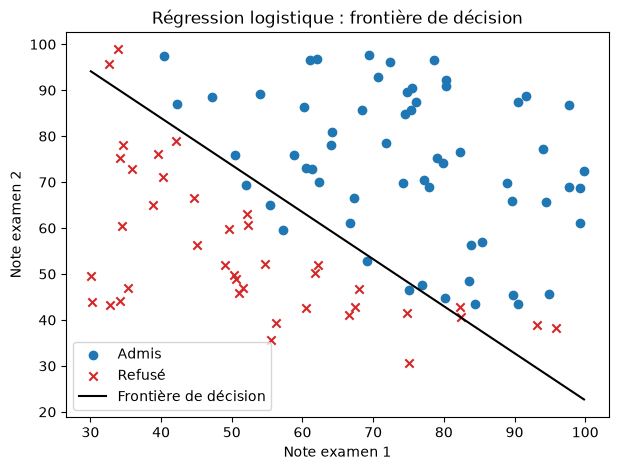

In [18]:
def plot_boundary(theta, X_raw, y, ax=None, label='Frontière de décision'):
    ax = plot_data(X_raw, y, ax)
    x1 = np.array([X_raw[:, 0].min(), X_raw[:, 0].max()])
    x2 = -(theta[0] + theta[1] * x1) / theta[2]
    ax.plot(x1, x2, 'k-', label=label)
    ax.legend()
    return ax

plt.figure(figsize=(7, 5))
plot_boundary(theta_opt, X_raw, y)
plt.title('Régression logistique : frontière de décision')
plt.show()

## 5. Évaluation

In [19]:
accuracy = (predict(theta_opt, X) == y).mean()
print(f"Précision sur l'ensemble d'entraînement : {accuracy:.1%}")

# Exemple : un étudiant avec 45 à l'examen 1 et 85 à l'examen 2
etudiant = np.array([1, 45, 85])
print(f"Probabilité d'admission (45, 85) : {predict_proba(theta_opt, etudiant):.1%}")

Précision sur l'ensemble d'entraînement : 89.0%
Probabilité d'admission (45, 85) : 77.6%


## 6. Descente de gradient codée à la main

Plutôt que de déléguer l'optimisation à SciPy, on implémente la descente de gradient :

$$
\theta \leftarrow \theta - \alpha\, \nabla_\theta J(\theta)
$$

Les notes vont de 30 à 100 environ : sans mise à l'échelle, les directions du problème sont très mal conditionnées et la descente converge très lentement. On **standardise** donc les variables (moyenne nulle, écart-type 1), puis on ramène les paramètres dans l'échelle d'origine.

In [20]:
def gradient_descent(X, y, alpha=1.0, n_iter=2000):
    """Descente de gradient à pas fixe. Renvoie theta et l'historique du coût."""
    theta = np.zeros(X.shape[1])
    history = np.empty(n_iter)
    for k in range(n_iter):
        theta -= alpha * compute_grad(theta, X, y)
        history[k] = compute_cost(theta, X, y)
    return theta, history


# Standardisation
mu, sigma = X_raw.mean(axis=0), X_raw.std(axis=0)
X_std = np.column_stack([np.ones(m), (X_raw - mu) / sigma])

theta_std, history = gradient_descent(X_std, y)

# Retour à l'échelle d'origine
theta_gd = np.empty(3)
theta_gd[1:] = theta_std[1:] / sigma
theta_gd[0] = theta_std[0] - np.sum(theta_std[1:] * mu / sigma)

print("theta (descente de gradient) =", np.round(theta_gd, 4))
print("theta (scipy)                =", np.round(theta_opt, 4))

theta (descente de gradient) = [-25.1613   0.2062   0.2015]
theta (scipy)                = [-25.1613   0.2062   0.2015]


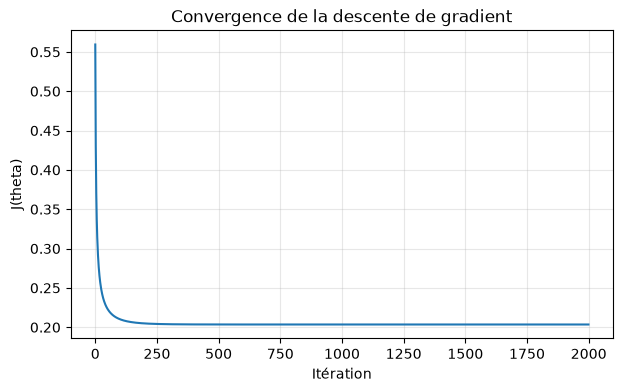

In [21]:
plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel('Itération')
plt.ylabel('J(theta)')
plt.title('Convergence de la descente de gradient')
plt.grid(alpha=0.3)
plt.show()

## 7. Comparaison avec scikit-learn

Par défaut, `LogisticRegression` ajoute une régularisation L2. On la rend négligeable avec un `C` très grand (C est l'inverse de la force de régularisation) pour résoudre le même problème.

In [22]:
clf = LogisticRegression(C=1e10, max_iter=10_000)
clf.fit(X_raw, y)
theta_sk = np.concatenate([clf.intercept_, clf.coef_.ravel()])

print("theta (scikit-learn) =", np.round(theta_sk, 4))
print(f"Précision scikit-learn : {clf.score(X_raw, y):.1%}")

theta (scikit-learn) = [-25.1614   0.2062   0.2015]
Précision scikit-learn : 89.0%


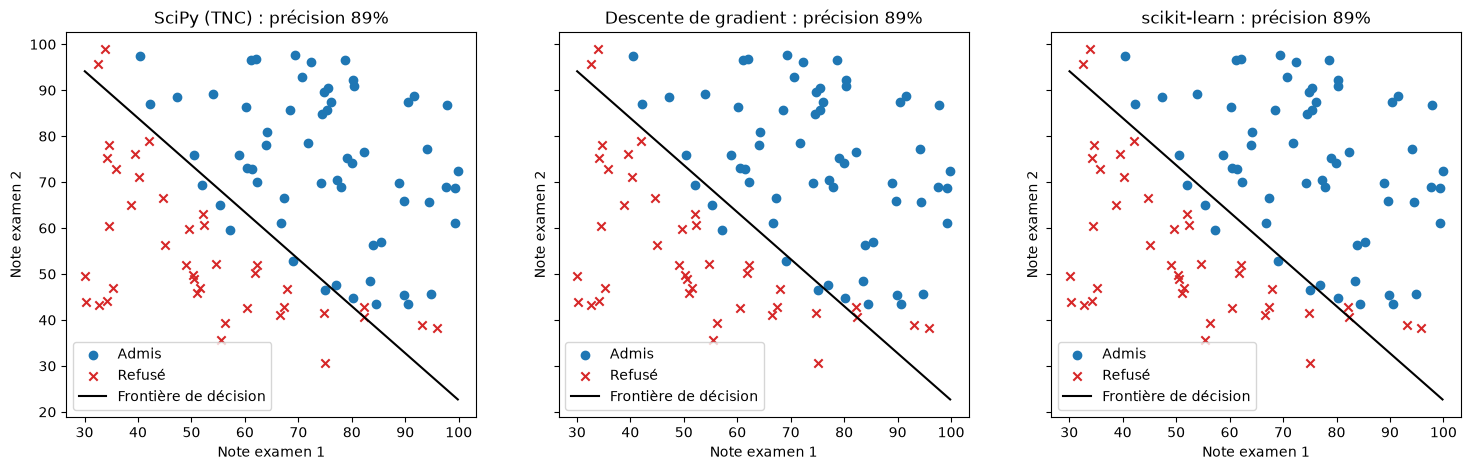

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for a, th, title in zip(ax, [theta_opt, theta_gd, theta_sk],
                        ['SciPy (TNC)', 'Descente de gradient', 'scikit-learn']):
    plot_boundary(th, X_raw, y, ax=a)
    a.set_title(f"{title} : précision {(predict(th, X) == y).mean():.0%}")
plt.show()

## 8. Conclusion

- Les trois approches convergent vers les mêmes paramètres, ce qui valide l'implémentation.
- Le modèle atteint environ 89 % de précision sur les données d'entraînement, avec une frontière de décision linéaire.
- La standardisation des variables est indispensable pour que la descente de gradient converge rapidement.

**Pistes d'amélioration :** évaluer le modèle sur un jeu de test séparé (ou par validation croisée), ajouter des variables polynomiales pour obtenir une frontière non linéaire, et introduire une régularisation pour limiter le surapprentissage.